In [1]:
# 16. Core Implementation and Fine-Tuning
from IPython.display import display
import numpy as np
import pandas as pd

from baseline_ner import LAB_DIR, SEED, load_conll_data

train_rows, test_rows, label_names = load_conll_data()
test_words = [row["tokens"] for row in test_rows]
outside_id = label_names.index("O")

import torch
from torch.utils.data import DataLoader
from transformers import AutoModelForTokenClassification, AutoTokenizer
from transformers import get_linear_schedule_with_warmup

CHECKPOINT = "google/bert_uncased_L-2_H-128_A-2"
IGNORE_INDEX = -100
BATCH_SIZE = 32
EPOCHS = 5
LEARNING_RATE = 2e-4
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
if device.type == "cuda":
    torch.set_float32_matmul_precision("high")

tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT, use_fast=True)
model = AutoModelForTokenClassification.from_pretrained(
    CHECKPOINT,
    id2label=dict(enumerate(label_names)),
    label2id={label: i for i, label in enumerate(label_names)},
).to(device)
MAX_LENGTH = model.config.max_position_embeddings


def first_subtoken_mask(word_ids):
    return [
        word_id is not None and (i == 0 or word_id != word_ids[i - 1])
        for i, word_id in enumerate(word_ids)
    ]


def encode_words(sentences, tags=None):
    encoded = tokenizer(
        sentences,
        is_split_into_words=True,
        truncation=True,
        max_length=MAX_LENGTH,
        padding=True,
        return_tensors="pt",
    )
    word_ids = [encoded.word_ids(i) for i in range(len(sentences))]
    masks = [first_subtoken_mask(ids) for ids in word_ids]
    for words, ids, mask in zip(sentences, word_ids, masks, strict=True):
        if [idx for idx, is_first in zip(ids, mask) if is_first] != list(range(len(words))):
            raise ValueError("A sentence lost word alignment during tokenization.")
    if tags is not None:
        encoded["labels"] = torch.tensor([
            [sentence_tags[idx] if is_first else IGNORE_INDEX for idx, is_first in zip(ids, mask)]
            for sentence_tags, ids, mask in zip(tags, word_ids, masks, strict=True)
        ])
    return encoded, word_ids, masks


def training_batch(rows):
    encoded, _, _ = encode_words(
        [row["tokens"] for row in rows],
        [row["ner_tags"] for row in rows],
    )
    return encoded


train_loader = DataLoader(
    train_rows,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=training_batch,
    generator=torch.Generator().manual_seed(SEED),
)

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
total_steps = EPOCHS * len(train_loader)
scheduler = get_linear_schedule_with_warmup(optimizer, total_steps // 10, total_steps)

print(f"Device = {device} | Strategy = first subtoken | Ignore index = {IGNORE_INDEX}", flush=True)
model.train()
for epoch in range(1, EPOCHS + 1):
    loss_sum = torch.zeros((), device=device)
    for batch in train_loader:
        optimizer.zero_grad(set_to_none=True)
        loss = model(**batch.to(device)).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        loss_sum += loss.detach()
    print(f"Epoch {epoch}/{EPOCHS} | Mean batch loss = {loss_sum.item() / len(train_loader):.4f}", flush=True)

model.eval()
demo_rows = [train_rows[3], train_rows[1]]
demo_words = [row["tokens"] for row in demo_rows]
demo_tags = [row["ner_tags"] for row in demo_rows]
demo, demo_word_ids, demo_masks = encode_words(demo_words, demo_tags)
with torch.inference_mode():
    demo_logits = model(**{key: demo[key].to(device) for key in tokenizer.model_input_names}).logits.cpu()

demo_ids = demo["input_ids"][0].tolist()
demo_predictions = demo_logits[0].argmax(dim=-1).tolist()
demo_table = pd.DataFrame({
    "tokens": tokenizer.convert_ids_to_tokens(demo_ids),
    "input_ids": demo_ids,
    "attention_mask": demo["attention_mask"][0].tolist(),
    "word_ids": pd.array(demo_word_ids[0], dtype="Int64"),
    "labels": demo["labels"][0].tolist(),
    "predictions": [
        label_names[label_id] if is_first else None
        for label_id, is_first in zip(demo_predictions, demo_masks[0])
    ],
})
for label, values in zip(label_names, demo_logits[0].T.numpy()):
    demo_table[f"logit[{label}]"] = values.round(3)
print(f"logits.shape = {tuple(demo_logits.shape)}")
display(demo_table)

from information_extraction import DEFAULT_CHECKPOINT

DEFAULT_CHECKPOINT.mkdir(parents=True, exist_ok=True)
model.save_pretrained(DEFAULT_CHECKPOINT)
tokenizer.save_pretrained(DEFAULT_CHECKPOINT)
print(f"Checkpoint = {DEFAULT_CHECKPOINT.relative_to(LAB_DIR)}")

C:\Users\Acer\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[transformers] BertForTokenClassification LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

Device = cuda | Strategy = first subtoken | Ignore index = -100


Epoch 1/5 | Mean batch loss = 0.6068


Epoch 2/5 | Mean batch loss = 0.1455


Epoch 3/5 | Mean batch loss = 0.1008


Epoch 4/5 | Mean batch loss = 0.0775


Epoch 5/5 | Mean batch loss = 0.0658


logits.shape = (2, 33, 9)


,tokens,input_ids,attention_mask,word_ids,labels,predictions,logit[O],logit[B-PER],logit[I-PER],logit[B-ORG],logit[I-ORG],logit[B-LOC],logit[I-LOC],logit[B-MISC],logit[I-MISC]
0,[CLS],101,1,<NA>,-100,None,5.788,-2.731,-4.059,-1.407,-1.781,-3.483,-3.995,-1.593,-2.803
1,the,1996,1,0,0,O,5.831,-3.539,-4.592,0.078,-2.159,-3.008,-4.008,-2.302,-3.829
2,european,2647,1,1,3,B-ORG,-1.193,-1.562,-2.396,6.225,0.499,1.884,-2.662,3.560,-1.871
3,commission,3222,1,2,4,I-ORG,1.486,-2.794,-2.677,0.222,5.047,-2.900,-0.771,-2.677,0.517
4,said,2056,1,3,0,O,6.438,-3.413,-3.558,-3.299,-2.251,-3.866,-3.125,-3.429,-2.707
5,on,2006,1,4,0,O,6.291,-2.367,-3.335,-2.276,-2.288,-3.859,-3.847,-3.483,-3.466
6,thursday,9432,1,5,0,O,6.434,-3.065,-3.881,-2.918,-2.427,-3.621,-3.329,-3.530,-3.009
7,it,2009,1,6,0,O,6.294,-2.136,-3.776,-2.282,-2.759,-3.464,-3.739,-3.682,-3.486
8,disagreed,18335,1,7,0,O,6.448,-3.238,-3.750,-3.097,-2.349,-3.975,-3.382,-3.418,-2.810
9,with,2007,1,8,0,O,6.482,-3.123,-3.862,-2.779,-2.574,-3.776,-3.636,-2.969,-3.117


Checkpoint = outputs\ner_checkpoint


CoNLL-2003 test = 3,453 sentences | Micro-averaged exact entity match


,Model,Precision,Recall,F1
0,Baseline,0.6628,0.7203,0.6903
1,Pretrained Transformer,0.7803,0.8107,0.7952


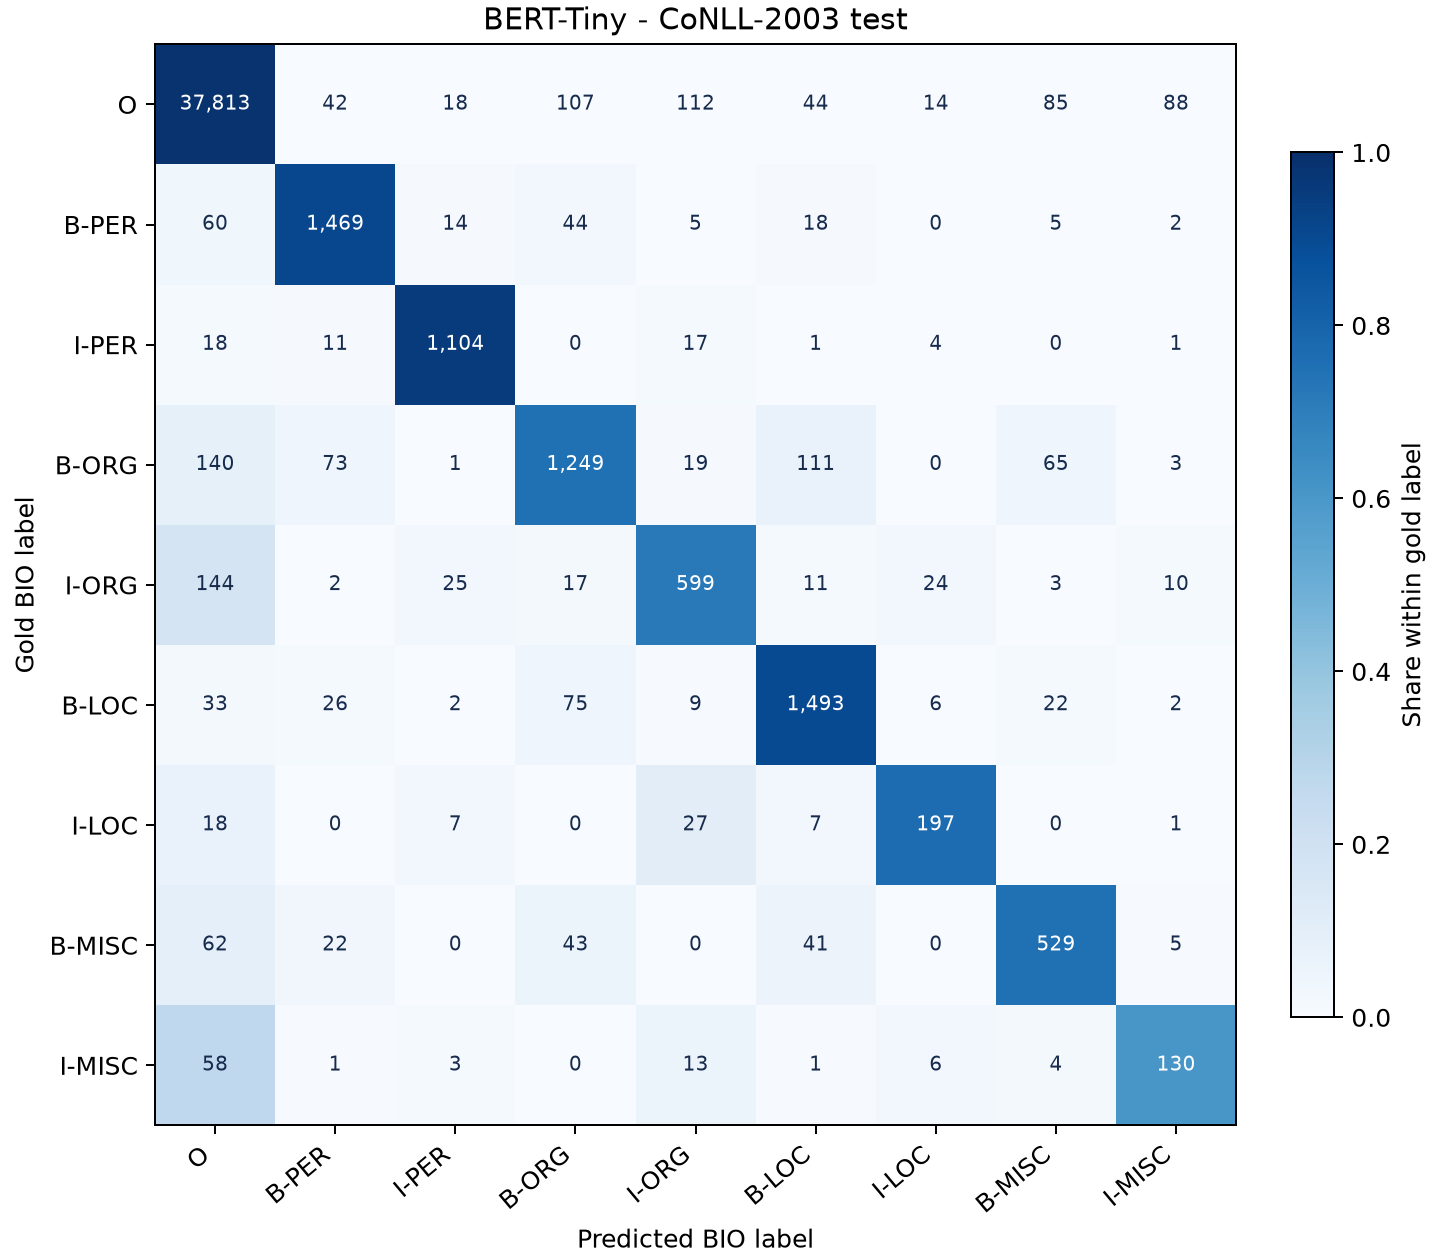

In [2]:
# 18. Experiment 2 - Baseline vs Transformer
from itertools import chain

import matplotlib.pyplot as plt
from IPython.display import Image
from sklearn.metrics import confusion_matrix

from baseline_ner import corpus_spans, entity_metrics, fit_baseline, predict_baseline

baseline = fit_baseline(train_rows)
baseline_predictions = predict_baseline(baseline, test_words, label_names)


@torch.inference_mode()
def predict_word_tags(sentences):
    model.eval()
    predictions = []
    for start in range(0, len(sentences), BATCH_SIZE):
        batch = sentences[start:start + BATCH_SIZE]
        encoded, _, masks = encode_words(batch)
        output_ids = model(**encoded.to(device)).logits.argmax(dim=-1).cpu().tolist()
        predictions.extend(
            [label_names[tag] for tag, is_first in zip(tags, mask) if is_first]
            for tags, mask in zip(output_ids, masks, strict=True)
        )
    return predictions


transformer_predictions = predict_word_tags(test_words)
gold_tags = [[label_names[label_id] for label_id in row["ner_tags"]] for row in test_rows]
for predicted_tags in (baseline_predictions, transformer_predictions):
    assert [len(tags) for tags in predicted_tags] == [len(tags) for tags in gold_tags]

gold_entities = corpus_spans(gold_tags)
baseline_entities = corpus_spans(baseline_predictions)
transformer_entities = corpus_spans(transformer_predictions)

comparison = pd.DataFrame([
    {"Model": "Baseline", **entity_metrics(gold_entities, baseline_entities)},
    {"Model": "Pretrained Transformer", **entity_metrics(gold_entities, transformer_entities)},
])
print(f"CoNLL-2003 test = {len(test_rows):,} sentences | Micro-averaged exact entity match")
display(comparison.round(4))
comparison.to_csv(LAB_DIR / "results.csv", index=False, float_format="%.8f")

gold_flat = list(chain.from_iterable(gold_tags))
predicted_flat = list(chain.from_iterable(transformer_predictions))
counts = confusion_matrix(gold_flat, predicted_flat, labels=label_names)
gold_totals = counts.sum(axis=1, keepdims=True)
row_share = np.divide(counts, gold_totals, out=np.zeros(counts.shape, dtype=float), where=gold_totals > 0)
assert counts.sum() == len(gold_flat)

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
heatmap = ax.imshow(row_share, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(label_names)), label_names, rotation=40, ha="right")
ax.set_yticks(range(len(label_names)), label_names)
ax.set(xlabel="Predicted BIO label", ylabel="Gold BIO label", title="BERT-Tiny - CoNLL-2003 test")
for row, col in np.ndindex(counts.shape):
    ax.text(col, row, f"{counts[row, col]:,}", ha="center", va="center",
            color="white" if row_share[row, col] >= 0.6 else "#172b4d", fontsize=8)
fig.colorbar(heatmap, ax=ax, label="Share within gold label", shrink=0.8)
confusion_path = LAB_DIR / "confusion_matrix.png"
fig.savefig(confusion_path, dpi=180, facecolor="white")
plt.close(fig)
display(Image(filename=str(confusion_path), width=700))

In [3]:
# 21. Experiment 4 - Entity Type Analysis
entity_type_results = pd.DataFrame([
    {
        "Entity": entity_type,
        **entity_metrics(
            {span for span in gold_entities if span[3] == entity_type},
            {span for span in transformer_entities if span[3] == entity_type},
        ),
    }
    for entity_type in ("PER", "ORG", "LOC", "MISC")
])
display(entity_type_results.round(4))
entity_type_results.to_csv(LAB_DIR / "entity_metrics.csv", index=False, float_format="%.8f")

,Entity,Precision,Recall,F1
0,PER,0.8478,0.8924,0.8695
1,ORG,0.7060,0.7098,0.7079
2,LOC,0.8420,0.8819,0.8615
3,MISC,0.6489,0.6923,0.6699


,Entity length,F1
0,1,0.7872
1,2,0.8429
2,3,0.6546
3,4+,0.3673


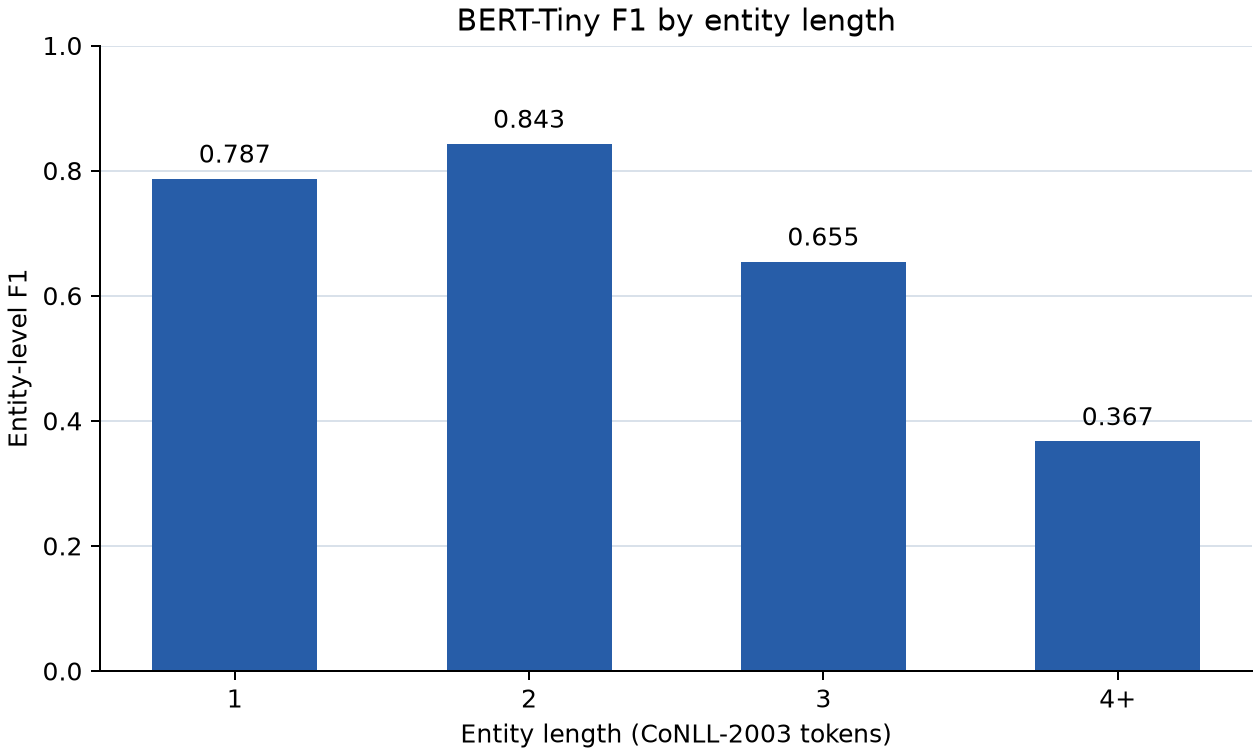

In [4]:
# 22. Experiment 5 - Entity Length
entity_length_results = pd.DataFrame([
    {
        "Entity length": label,
        "F1": entity_metrics(
            {span for span in gold_entities if min(span[2] - span[1], 4) == size},
            {span for span in transformer_entities if min(span[2] - span[1], 4) == size},
        )["F1"],
    }
    for size, label in enumerate(("1", "2", "3", "4+"), start=1)
])
display(entity_length_results.round(4))

fig, ax = plt.subplots(figsize=(7, 4.2), layout="constrained")
bars = ax.bar(entity_length_results["Entity length"], entity_length_results["F1"],
              color="#275da8", width=0.56)
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.set(ylim=(0, 1), xlabel="Entity length (CoNLL-2003 tokens)", ylabel="Entity-level F1",
       title="BERT-Tiny F1 by entity length")
ax.set_axisbelow(True)
ax.grid(axis="y", color="#d9e1ea", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
length_path = LAB_DIR / "entity_length_analysis.png"
fig.savefig(length_path, dpi=180, facecolor="white")
plt.close(fig)
display(Image(filename=str(length_path), width=700))

In [5]:
# 23. Experiment 6 - Error Analysis
from IPython.display import HTML

from baseline_ner import bio_spans

EXAMPLES_PER_TYPE = 5
SPURIOUS = "False positive (spurious entity)"
MISSING = "False negative (missing entity)"
BOUNDARY = "Boundary error (wrong boundary)"
examples_by_type = {error_type: [] for error_type in (SPURIOUS, MISSING, BOUNDARY)}


def overlaps(left, right):
    return left[0] < right[1] and right[0] < left[1]


def describe_span(words, span):
    if span is None:
        return "—"
    start, end, label = span
    return f"{' '.join(words[start:end])} [{label}]"


def make_error_row(words, gold, prediction, error_type):
    if error_type == SPURIOUS:
        explanation = (
            f"Mô hình gán nhãn {prediction[2]} cho cụm này. "
            "Gold gán nhãn O cho tất cả các từ trong cụm."
        )
    elif error_type == MISSING:
        explanation = (
            f"Gold đánh dấu cụm này là {gold[2]}. "
            "Mô hình gán nhãn O cho tất cả các từ trong cụm."
        )
    else:
        gold_start, gold_end, label = gold
        pred_start, pred_end, _ = prediction
        changed_parts = [
            f"{action} «{' '.join(words[start:end])}»"
            for start, end, action in (
                (gold_start, pred_start, "bỏ ở đầu cụm"),
                (pred_start, gold_start, "thêm vào đầu cụm"),
                (pred_end, gold_end, "bỏ ở cuối cụm"),
                (gold_end, pred_end, "thêm vào cuối cụm"),
            )
            if start < end
        ]
        explanation = f"Mô hình nhận đúng loại {label} nhưng " + " và ".join(changed_parts) + "."

    return {
        "Text": " ".join(words),
        "Gold": describe_span(words, gold),
        "Prediction": describe_span(words, prediction),
        "Error type": error_type,
        "Explanation": explanation,
    }


def find_boundary_pair(gold_spans, predicted_spans):
    for gold in gold_spans:
        overlapping_predictions = [span for span in predicted_spans if overlaps(gold, span)]
        if len(overlapping_predictions) != 1:
            continue
        prediction = overlapping_predictions[0]
        if prediction != gold and prediction[2] == gold[2]:
            if sum(overlaps(prediction, span) for span in gold_spans) == 1:
                return gold, prediction
    return None


for words, gold_sequence, predicted_sequence in zip(
    test_words, gold_tags, transformer_predictions, strict=True,
):
    if all(len(rows) == EXAMPLES_PER_TYPE for rows in examples_by_type.values()):
        break
    gold_spans = list(bio_spans(gold_sequence))
    predicted_spans = list(bio_spans(predicted_sequence))

    if len(examples_by_type[SPURIOUS]) < EXAMPLES_PER_TYPE:
        spurious = next(
            (span for span in predicted_spans if not any(overlaps(span, gold) for gold in gold_spans)),
            None,
        )
        if spurious is not None:
            examples_by_type[SPURIOUS].append(make_error_row(words, None, spurious, SPURIOUS))
            continue

    if len(examples_by_type[MISSING]) < EXAMPLES_PER_TYPE:
        missing = next(
            (span for span in gold_spans if not any(overlaps(span, pred) for pred in predicted_spans)),
            None,
        )
        if missing is not None:
            examples_by_type[MISSING].append(make_error_row(words, missing, None, MISSING))
            continue

    if len(examples_by_type[BOUNDARY]) < EXAMPLES_PER_TYPE:
        boundary_pair = find_boundary_pair(gold_spans, predicted_spans)
        if boundary_pair is not None:
            gold, prediction = boundary_pair
            examples_by_type[BOUNDARY].append(make_error_row(words, gold, prediction, BOUNDARY))

error_counts = {error_type: len(rows) for error_type, rows in examples_by_type.items()}
if any(count < EXAMPLES_PER_TYPE for count in error_counts.values()):
    raise ValueError(f"Insufficient distinct error examples in the test set: {error_counts}")

error_analysis = pd.DataFrame.from_records(chain.from_iterable(examples_by_type.values()))
print("Gold and Prediction show the spans involved in each error. — indicates no entity.")
display(HTML(error_analysis.to_html(index=False)))

Gold and Prediction show the spans involved in each error. — indicates no entity.


Text,Gold,Prediction,Error type,Explanation
"Japan , co-hosts of the World Cup in 2002 and ranked 20th in the world by FIFA , are favourites to regain their title here .",—,co-hosts [MISC],False positive (spurious entity),Mô hình gán nhãn MISC cho cụm này. Gold gán nhãn O cho tất cả các từ trong cụm.
"Bitar saved well again from Miura in the 37th minute , parrying away his header from a corner .",—,parrying [PER],False positive (spurious entity),Mô hình gán nhãn PER cho cụm này. Gold gán nhãn O cho tất cả các từ trong cụm.
Ijaz Ahmad c Spearman b Vaughan 59,—,b [PER],False positive (spurious entity),Mô hình gán nhãn PER cho cụm này. Gold gán nhãn O cho tất cả các từ trong cụm.
"Cairns 8-1-35-1 ( w-2 ) , Vaughan 9-1-55-1 , Harris 10-0-42-5 ( w-1 ) ,",—,w-2 [PER],False positive (spurious entity),Mô hình gán nhãn PER cho cụm này. Gold gán nhãn O cho tất cả các từ trong cụm.
S. Doull c subs ( M. Wasim ) b Waqar 1,—,subs [PER],False positive (spurious entity),Mô hình gán nhãn PER cho cụm này. Gold gán nhãn O cho tất cả các từ trong cụm.
Bitar pulled off fine saves whenever they did .,Bitar [PER],—,False negative (missing entity),Gold đánh dấu cụm này là PER. Mô hình gán nhãn O cho tất cả các từ trong cụm.
RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A YEAR .,CUTTITTA [PER],—,False negative (missing entity),Gold đánh dấu cụm này là PER. Mô hình gán nhãn O cho tất cả các từ trong cụm.
"Stefano Bordon is out through illness and Coste said he had dropped back row Corrado Covi , who had been recalled for the England game after five years out of the national team .",Coste [PER],—,False negative (missing entity),Gold đánh dấu cụm này là PER. Mô hình gán nhãn O cho tất cả các từ trong cụm.
"A minute later , Bitar produced a good double save , first from Kazuyoshi Miura 's header and then blocked a Takagi follow-up shot .",Bitar [PER],—,False negative (missing entity),Gold đánh dấu cụm này là PER. Mô hình gán nhãn O cho tất cả các từ trong cụm.
Japan started the second half brightly but Bitar denied them an equaliser when he dived to his right to save Naoki Soma 's low drive in the 53rd minute .,Bitar [PER],—,False negative (missing entity),Gold đánh dấu cụm này là PER. Mô hình gán nhãn O cho tất cả các từ trong cụm.


In [6]:
# 25-27. Information Extraction and Evaluation
import json

from information_extraction import DEFAULT_CHECKPOINT, DEMO_TEXT, evaluate_extraction, extract_information
from information_extraction import load_ner_checkpoint

ie_tokenizer, ie_model = load_ner_checkpoint(DEFAULT_CHECKPOINT)
structured = extract_information(DEMO_TEXT, ie_tokenizer, ie_model)
print(DEMO_TEXT)
print(json.dumps(structured, ensure_ascii=False, indent=2))

ie_metrics = evaluate_extraction(test_rows, label_names, ie_tokenizer, ie_model)
print("CoNLL-2003 test subset | Exact character span and type match")
display(pd.DataFrame([ie_metrics]).round(4))

Barack Obama spoke at Harvard University in Boston. Bill Gates attended a conference at Stanford University in California.
{
  "PERSON": [
    "Barack Obama",
    "Bill Gates"
  ],
  "ORGANIZATION": [
    "Harvard University",
    "Stanford University"
  ],
  "LOCATION": [
    "Boston",
    "California"
  ]
}
CoNLL-2003 test subset | Exact character span and type match


,Sentences,Gold,Predicted,Precision,Recall,F1
0,30,29,42,0.5714,0.8276,0.6761
